# Drought stripes (updated version)

In [2]:
import pygrib
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 16
#plt.rcParams["font.family"] = "Arial"
plt.rcParams['font.serif'] = ['Times New Roman']
import matplotlib.colors as colors
from matplotlib.colors import BoundaryNorm
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import eccodes as ec
import os
import scipy.stats as stats
import statsmodels.api as statsmodels
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
#import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
import regionmask 

#sys.path.insert(0, '..')
#sys.path.insert(0, '../..')

In [3]:
# import helper functions
print(os.getcwd())
from helpers.helpers_plotting import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap#, plot_countrymap
from helpers.helpers import identify_events, count_events, sum_dict_lists, get_event_duration, count_occurrences
from helpers.geodata import calculate_gridarea, grid2df, mask_gridpoints_in_polygon, mask_3darray
from helpers.helpers_ecmwf import load_grb_file
from spidi.spidi.spidi import calculate_si
from spidi.spidi.helpers import convert_mmperday_to_mmpermonth

/etc/ecmwf/nfs/dh2_home_a/nejk/code/droughts_hist


## Main settings

In [3]:
# settings
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
debug = True
#country = ["Somalia","Somaliland"]
#country_name = 'Somalia'
admin = ["California"]
admin_name = 'California'

In [4]:
# paths
ipath         = "/ec/vol/centaur/nejk/drought_monitor/"
drought_index = "SPEI"
windows       = [12]
ref_period    = "1991to2020"
stream        = "moda"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:10])
print(ryyyy_start)
print(ryyyy_end)
yyyy_start    = "1940"
yyyy_end      = "2023"
print(yyyy_start)
print(yyyy_end)

1991
2020
1940
2023


### Create color scheme

In [5]:
# create colorscheme
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]

### Handle dates

In [6]:
dates = pd.date_range(start="1940-01-01",end="2024-01-01", freq='M')
print(dates)
print(dates.size)

DatetimeIndex(['1940-01-31', '1940-02-29', '1940-03-31', '1940-04-30',
               '1940-05-31', '1940-06-30', '1940-07-31', '1940-08-31',
               '1940-09-30', '1940-10-31',
               ...
               '2023-03-31', '2023-04-30', '2023-05-31', '2023-06-30',
               '2023-07-31', '2023-08-31', '2023-09-30', '2023-10-31',
               '2023-11-30', '2023-12-31'],
              dtype='datetime64[ns]', length=1008, freq='ME')
1008


/etc/ecmwf/ssd/ssd1/ecinteractive/nejk-ecinteractive/tmpdirs/nejk.29161274/ipykernel_1669002/3832646475.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start="1940-01-01",end="2024-01-01", freq='M')


In [7]:
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(type(pdate_seq))

<class 'list'>


## Country data

This is the simplified bit! Use regionmask's countries and functions directly

<GeoAxes: >

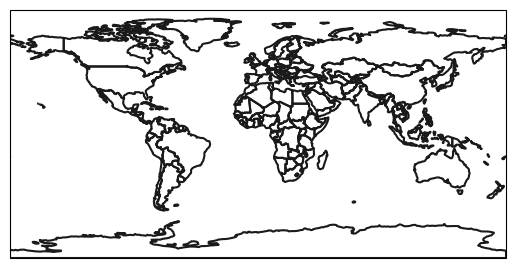

In [8]:
#regionmask.defined_regions.natural_earth.countries_110.plot(add_label=False)
regionmask.defined_regions.natural_earth_v5_0_0.countries_110.plot(add_label=False)

<GeoAxes: >

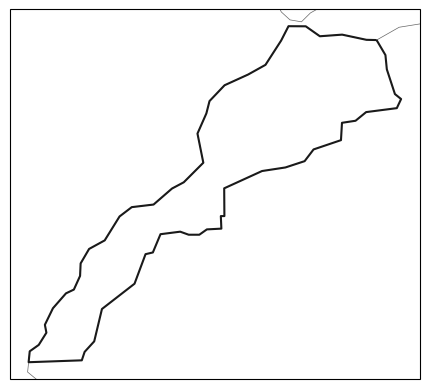

In [9]:
#regionmask.defined_regions.natural_earth.countries_110[country].plot(add_label=False)
regionmask.defined_regions.natural_earth_v5_0_0.countries_110[country].plot(add_label=False)

### Read landmask

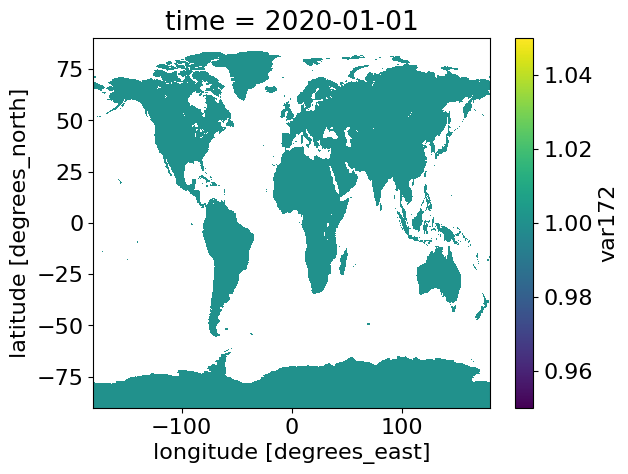

In [10]:
# read landmasks
varname       = "var172"
# binary mask (0/1)
ifile_name    = "landmask_era5_global.nc"
ifile         = os.path.join("/home/nejk/code/drought_on_demand/masks", ifile_name)
landmask_ecm = xr.open_dataset(ifile)[varname]
landmask_ecm = landmask_ecm.where( landmask_ecm.values == 1 )
landmask_ecm.plot()
nc_f = nc4.Dataset(ifile)
lats = np.asarray(nc_f["lat"][:])
lons = np.asarray(nc_f["lon"][:])
grid_lon, grid_lat = np.meshgrid(lons, lats)

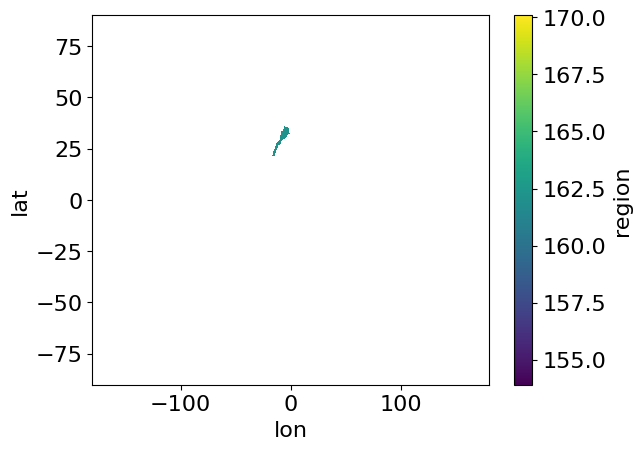

In [11]:
# mask country data
#gpoints = grid2df(grid_lon, grid_lat, ret='gpd', crs='epsg:4326')
#mask    = mask_gridpoints_in_polygon(gpoints, countryshp, return_shape=grid_lon.shape, crs='epsg:4326')
# mask country data -now using regionmask
#mask = regionmask.defined_regions.natural_earth.countries_110[country].mask(lons, lats)
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[country].mask(lons, lats)
mask.plot()

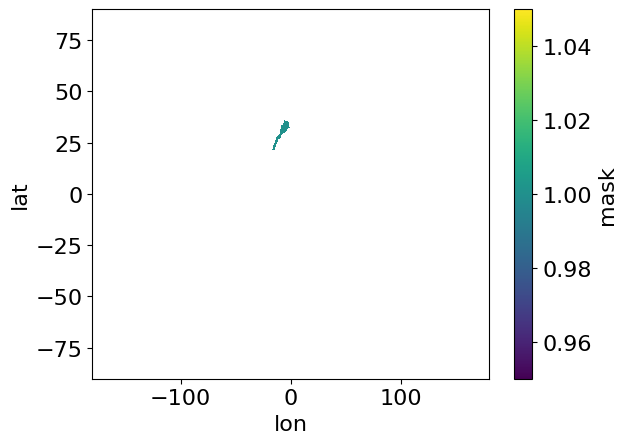

In [12]:
# set mask values to np.nan / 1
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

## Reanalysis data

### Read precipitation data

In [13]:
if drought_index == "SPI":
    ifile_name    = f"forcing/precipitation_era5_global_19400101to20231201"
    ifile         = os.path.join(ipath, ifile_name)
    precip        = load_grb_file(ifile)
    print(precip.shape)
    # reshape to 3D array of dimension time x lat x lon for writing to netCDF
    precip        = precip.reshape((precip.shape[0], lats.size, lons.size))
    #for it in range(len(precip.shape[0])):
    #    # multiply with number of days in each month to get monthly totals
    #    precip[it,:,:] = precip[it,:,:] * 
    print(precip.shape)

In [14]:
if drought_index == "SPI":
    #precip_country= mask_3darray(precip, mask, maskval=1, fillval=np.nan)
    precip_country = precip.where(mask)

    print(precip_country.shape)
    #plt.figure()
    #plt.pcolormesh(precip_country[14,:,:])
    #plt.colorbar()

### Read P-PET data

In [16]:
if drought_index == "SPEI":
    ifile_name    = f"forcing/precipitation_minus_potential_evaporation_global_19400101to20231201"
    ifile         = os.path.join(ipath, ifile_name)
    pmpet         = load_grb_file(ifile)
    print(pmpet.shape)
    # reshape to 3D array of dimension time x lat x lon for writing to netCDF
    pmpet         = pmpet.reshape((pmpet.shape[0], lats.size, lons.size))
    xr.DataArray
    #for it in range(len(precip.shape[0])):
    #    # multiply with number of days in each month to get monthly totals
    #    precip[it,:,:] = precip[it,:,:] * 
    print(pmpet.shape)

(1008, 1038240)
(1008, 721, 1440)


In [ ]:
if drought_index == "SPEI":
    #pmpet_country= mask_3darray(pmpet, mask, maskval=1, fillval=np.nan)
    pmpet_country = pmpet.where(mask)

    print(pmpet_country.shape)

## Country-based drought indicators

In [ ]:
# Use regionmask's weights instead of calculating areas etc
weights = np.cos(np.deg2rad(lats))

### Calulate average P or P-PET

In [ ]:
if drought_index == "SPI":

    precip_country = airtemps.where(mask_CNA)

    for it in range(len(precip_country_ts)):
        #precip_country_ts[it] = np.nansum(precip_country[it,:,:] * country_area_2d / country_area_total)
        precip_country_ts[it] = np.nansum(precip_country[it,:,:] * country_area_2d / country_area_total)
        precip_country_ts[it] = airtemps_CNA.weighted(weights).mean(dim=("lat", "lon")) - 273.15

    print(precip_country_ts.shape)
    print(dates.size)
    plt.figure()
    plt.plot(dates, precip_country_ts)
    

In [ ]:
pmpet_country_ts = np.zeros(pmpet_country.shape[0])
if drought_index == "SPEI":
    
    for it in range(len(pmpet_country_ts)):
        pmpet_country_ts[it] = np.nansum(pmpet_country[it,:,:] * country_area_2d / country_area_total)
    
    print(pmpet_country_ts.shape)
    print(dates.size)
    plt.figure()
    plt.plot(dates, pmpet_country_ts)
    

### Calculate drought indicator

In [ ]:
if drought_index == "SPI":

    spi_country_ts = {}
        
    dfdata = pd.DataFrame(precip_country_ts, index=pdate_seq)
    dfdata.index = pd.to_datetime(dfdata.index)
    dfdata = convert_mmperday_to_mmpermonth(dfdata, list(dfdata.columns.values))
    dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) ]
    #dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) & (dfdata.index.month == 12) ]
    
    print((dfdata.index.year >= ryyyy_start).any())
    print((dfdata.index.year <= ryyyy_end).any())
    print(ryyyy_end)
    print((dfdata_ref))
    
    
    for window in windows:
        print(f"Processing country average of {drought_index.lower()}{window}...")
    
        tspi_country = calculate_si(dfdata, dfdata_ref = dfdata_ref, window = window, distribution = 'gamma', integration_frequency_string = '%m-%d',
            n_events_min = 5, max_zeros = 0.99, remove_zeros = True, pzero_replace = True, pzero_center_mass = True)[f"si{window}_0"]
        
        # write to dictionary
        ivar      = f"{drought_index.lower()}{window}"
        spi_country_ts[ivar] = tspi_country.values[:]
        del(tspi_country)
    
        plt.figure()
        plt.plot(dates, spi_country_ts[ivar])

In [ ]:
if drought_index == "SPEI":

    spei_country_ts = {}
        
    dfdata = pd.DataFrame(pmpet_country_ts, index=pdate_seq)
    dfdata.index = pd.to_datetime(dfdata.index)
    dfdata = convert_mmperday_to_mmpermonth(dfdata, list(dfdata.columns.values))
    dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) ]
    
    print((dfdata.index.year >= ryyyy_start).any())
    print((dfdata.index.year <= ryyyy_end).any())
    print(ryyyy_end)
    print((dfdata_ref))
    
    
    for window in windows:
        print(f"Processing country average of {drought_index.lower()}{window}...")
    
        tspi_country = calculate_si(dfdata, dfdata_ref = dfdata_ref, window = window, distribution = 'genlogistic', integration_frequency_string = '%m-%d',
            n_events_min = 5, max_zeros = 0.99, remove_zeros = False, pzero_replace = False, pzero_center_mass = False)[f"si{window}_0"]
        
        # write to dictionary
        ivar      = f"{drought_index.lower()}{window}"
        spei_country_ts[ivar] = tspi_country.values[:]
        del(tspi_country)
    
        plt.figure()
        plt.plot(dates, spei_country_ts[ivar])

## Plots...

### Normal SPI/SPEI plot

In [ ]:
for window in windows:
    ivar      = f"{drought_index.lower()}{window}"

    plt.figure(figsize=(18,4))
    x = dates[(window-1)::window]
    xyear = [ix.year for ix in x]
    if drought_index == "SPI":
        y = list(spi_country_ts[ivar][(window-1)::window])
    if drought_index == "SPEI":
        y = list(spei_country_ts[ivar][(window-1)::window])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, y, color=y_colors, align='center', width=365/(12/window))
    print(x[xyear.index(ryyyy_end)])
    plt.axvspan(x[xyear.index(ryyyy_start)], x[xyear.index(ryyyy_end)], facecolor='#CCCCCC', alpha=0.5)
    plt.bar(x, y, color=y_colors, align='center', width=365/(12/window))
    plt.axhline(y=0, color = 'black', linestyle = '-')
    #plt.xlabel("Date")
    plt.ylabel(f"{drought_index}–{window} [–]")
    plt.title(f"{drought_index}–{window} over {country_name}")

    # custom legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color=color_list[0], lw=4),
                    Line2D([0], [0], color=color_list[1], lw=4),
                    Line2D([0], [0], color=color_list[2], lw=4),
                    #Line2D([0], [0], color=color_list[3], lw=4),
                    Line2D([0], [0], color='#7F7F7F', lw=4),
                    #Line2D([0], [0], color=color_list[5], lw=4),
                    Line2D([0], [0], color=color_list[6], lw=4),
                    Line2D([0], [0], color=color_list[7], lw=4),
                    Line2D([0], [0], color=color_list[8], lw=4)]

    #plt.legend(custom_lines, ['extremely dry', 'severely dry', 'moderately dry','near-normal','moderately wet','severely wet','extremely wet'], ncol=7, loc='upper center')
    #print(y)
        
    del(x)
    del(y)
    del(y_colors)

### Drought Stripes

In [ ]:
for window in windows:
    plt.figure(figsize=(24,4))
    plt.axis('off')
    x = dates[(window-1)::window]
    xyear = [ix.year for ix in x]
    if drought_index == "SPI":
        y = list(spi_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
    if drought_index == "SPEI":
        y = list(spei_country_ts[f"{drought_index.lower()}{window}"][(window-1)::window])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, np.repeat(1, len(x)), color=y_colors, align='center', width=365/(12/window))
    #fig.axes.get_xaxis().set_visible(False)
    #fig.axes.get_yaxis().set_visible(False)
    plt.savefig(f"{country_name}_{drought_index}{window}.png", facecolor="white",  edgecolor='none')
    plt.savefig(f"{country_name}_{drought_index}{window}.pdf", facecolor="white",  edgecolor='none')
